<a href="https://colab.research.google.com/github/kaczynskimat/greenlab/blob/main/analysis/google_colab_r.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Google Colab R

- Google is now supporting a Colab notebook with the R kernel
- We can run R codes directly on Colab
- R Colab Notebook Link: [R Google Colab](https://colab.fan/r)
    - Colab with R kernel
    - With base-R installed
    - Run R codes immediately
    - No need to setup
    - Save a copy in your Drive


## Demonstration

This notebook uses the R kernel.


In [178]:
# Check the R version and loaded packages
sessionInfo()

R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.4 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] jsonlite_2.0.0  lubridate_1.9.5 forcats_1.0.1   stringr_1.6.0  
 [5] dplyr_1.2.1     purrr_1.2.2     readr_2.2.0     tidyr_1.3.2    
 [9] tibble_3.3.1    ggplot2_4.0.3   tidy

In [179]:

# Packages used for data handling and plots
library(ggplot2)
library(dplyr)

In [181]:
# Install the packages if they are not already available
required_pkgs <- c("tidyverse", "jsonlite")
new_pkgs <- required_pkgs[!(required_pkgs %in% installed.packages()[, "Package"])]

if (length(new_pkgs) > 0) {
  install.packages(new_pkgs)
}

library(tidyverse)
library(jsonlite)

In [182]:
url <- "https://raw.githubusercontent.com/kaczynskimat/greenlab/main/experiment/shared-results/2026-10-20/run_table.csv"
raw <- read_csv(url, show_col_types = FALSE)

cat("Raw dataset dimensions:", nrow(raw), "rows x", ncol(raw), "columns\n")

# Keep runs that finished successfully
clean_runs <- raw %>%
  filter(`__done` == "DONE")

cat("Completed runs:", nrow(clean_runs), "out of", nrow(raw), "\n\n")

Raw dataset dimensions: 9600 rows x 16 columns
Completed runs: 4193 out of 9600 



In [183]:
# Check for missing values in the completed runs
na_counts <- colSums(is.na(clean_runs))
print(na_counts[na_counts > 0])

if (all(na_counts == 0)) {
  cat("No missing values found.\n\n")
}

named numeric(0)
No missing values found.



In [184]:
# Look for impossible or suspicious energy measurements
energy_anomalies <- clean_runs %>%
  filter(package_energy_j <= 0 | dram_energy_j < 0)

cat("Rows with non-positive package energy or negative DRAM energy:",
    nrow(energy_anomalies), "\n\n")


Rows with non-positive package energy or negative DRAM energy: 0 



In [185]:
# Get the repetition number from each run ID
clean_runs <- clean_runs %>%
  mutate(
    repetition = as.integer(str_extract(`__run_id`, "(?<=repetition_)\\d+")),
    run_seq = as.integer(str_extract(`__run_id`, "(?<=run_)\\d+")),
    variant = as.character(variant)
  )

# Check that original and modified runs used the same workload
workload_mismatches <- clean_runs %>%
  group_by(problem, variant, repetition) %>%
  summarise(
    n_treatments = n_distinct(treatment),
    n_seeds = n_distinct(workload_seed),
    n_hashes = n_distinct(workload_sha256),
    .groups = "drop"
  ) %>%
  filter(n_treatments == 2 & (n_seeds > 1 | n_hashes > 1))

cat("Pairs with different workload seeds or hashes:",
    nrow(workload_mismatches), "\n\n")

Pairs with different workload seeds or hashes: 0 



In [186]:
# Count the measurements available for each snippet
snippet_counts <- clean_runs %>%
  count(problem, variant, treatment, name = "repetitions")

cat("Distinct snippets:", nrow(snippet_counts), "(expected: 96)\n")
cat("Minimum repetitions:", min(snippet_counts$repetitions), "\n")
cat("Median repetitions:", median(snippet_counts$repetitions), "\n")
cat("Mean repetitions:", round(mean(snippet_counts$repetitions), 1), "\n")
cat("Maximum repetitions:", max(snippet_counts$repetitions), "\n\n")

head(snippet_counts, 10)

Distinct snippets: 96 (expected: 96)
Minimum repetitions: 37 
Median repetitions: 43.5 
Mean repetitions: 43.7 
Maximum repetitions: 56 



problem,variant,treatment,repetitions
<dbl>,<chr>,<chr>,<int>
3,1,modified,38
3,1,original,38
3,2,modified,40
3,2,original,40
3,3,modified,45
3,3,original,45
15,1,modified,45
15,1,original,45
15,2,modified,45


In [187]:
# Map each problem ID to its name, difficulty and guideline
metadata <- tribble(
  ~problem, ~name,                                            ~difficulty, ~guideline_id, ~guideline_family,
       387, "First Unique Character in a String",             "easy",      "G1",          "Code Optimization",
         3, "Longest Substring Without Repeating Characters", "medium",    "G1",          "Code Optimization",
       977, "Squares of a Sorted Array",                      "easy",      "G2",          "Code Optimization",
       240, "Search a 2D Matrix II",                          "medium",    "G2",          "Code Optimization",
       605, "Can Place Flowers",                              "easy",      "G3",          "Code Optimization",
        15, "3Sum",                                           "medium",    "G3",          "Code Optimization",
       383, "Ransom Note",                                    "easy",      "G6",          "Code Optimization",
       442, "Find All Duplicates in an Array",                "medium",    "G6",          "Code Optimization",
       509, "Fibonacci Number",                               "easy",      "G18",         "Function Calls",
       322, "Coin Change",                                    "medium",    "G18",         "Function Calls",
       125, "Valid Palindrome",                               "easy",      "G19",         "Function Calls",
       200, "Number of Islands",                              "medium",    "G19",         "Function Calls",
       867, "Transpose Matrix",                               "easy",      "G24",         "Other",
       238, "Product of Array Except Self",                   "medium",    "G24",         "Other",
       905, "Sort Array By Parity",                           "easy",      "G27",         "Other",
        49, "Group Anagrams",                                 "medium",    "G27",         "Other"
)

In [188]:
# Compute Total Energy E and Power P
runs_with_metrics <- clean_runs %>%
  mutate(
    problem        = as.integer(problem), # convert the problem id to integer so that it matches the data type in our metadata table
    variant        = as.character(variant),
    total_energy_j = package_energy_j + dram_energy_j, # calculcate total energy
    total_power_w  = total_energy_j / measurement_duration_seconds # calculate total power in watts
  )

In [189]:
# Summarise the measurements for each problem, variant and treatment
snippet_table <- runs_with_metrics %>%
  group_by(problem, variant, treatment) %>%
  summarise(
    n_repetitions = n(),
    energy_total_median = median(total_energy_j),
    energy_pkg_median = median(package_energy_j),
    runtime_median = median(benchmark_runtime_seconds),
    power_median = median(total_power_w),
    cpu_median = median(avg_cpu_usage_percent),
    rss_median = median(avg_rss_bytes),
    energy_total_mean = mean(total_energy_j),
    energy_pkg_mean = mean(package_energy_j),
    runtime_mean = mean(benchmark_runtime_seconds),
    power_mean = mean(total_power_w),
    cpu_mean = mean(avg_cpu_usage_percent),
    rss_mean = mean(avg_rss_bytes),
    .groups = "drop"
  ) %>%
  left_join(metadata, by = "problem")

cat("Rows in snippet summary:", nrow(snippet_table), "(expected: 96)\n\n")


Rows in snippet summary: 96 (expected: 96)



In [190]:

# separate the 2 types of treatments (original and modified) to create an inner join in order to compare the deltas from our experiment planning part
orig <- snippet_table %>%
  filter(treatment == "original") %>%
  select(problem, variant, name, difficulty, guideline_id, guideline_family,
         n_reps_orig = n_repetitions,
         starts_with("energy_"), starts_with("runtime_"),
         starts_with("power_"), starts_with("cpu_"), starts_with("rss_"))
mod <- snippet_table %>%
  filter(treatment == "modified") %>%
  select(problem, variant,
         n_reps_mod = n_repetitions,
         starts_with("energy_"), starts_with("runtime_"),
         starts_with("power_"), starts_with("cpu_"), starts_with("rss_"))

# create 48 matched pairs
pair_table <- inner_join(
  orig, mod,
  by = c("problem", "variant"),
  suffix = c("_orig", "_mod")
) %>%
  mutate(
    # Positive values mean the modified version used less energy or fewer resources

    # Absolute and relative energy savings
    dE = energy_total_median_orig - energy_total_median_mod,
    dE_rel = dE / energy_total_median_orig,

    # Additional energy comparisons for sensitivity analysis
    dE_pkg = energy_pkg_median_orig - energy_pkg_median_mod,
    dE_mean = energy_total_mean_orig - energy_total_mean_mod,

    # Runtime, Power, CPU, Memory relative deltas
    dT_rel      = (runtime_median_orig - runtime_median_mod) / runtime_median_orig,
    dP_rel      = (power_median_orig - power_median_mod) / power_median_orig,
    dCPU_rel    = (cpu_median_orig - cpu_median_mod) / cpu_median_orig,
    dMem_rel    = (rss_median_orig - rss_median_mod) / rss_median_orig
  )


In [191]:
# Save the summary tables for later
write_csv(snippet_table, "snippet_summary.csv")
write_csv(pair_table, "paired_deltas.csv")

cat("Rows in paired table:", nrow(pair_table), "(expected: 48)\n")
cat("Saved snippet_summary.csv and paired_deltas.csv\n\n")

# Preview of 10 elements in the table
pair_table %>%
  select(problem, variant, guideline_id, difficulty, dE, dE_rel, dT_rel, dP_rel, dMem_rel) %>%
  head(10) %>%
  print()

Rows in paired table: 48 (expected: 48)
Saved snippet_summary.csv and paired_deltas.csv

# A tibble: 10 × 9
   problem variant guideline_id difficulty     dE   dE_rel    dT_rel    dP_rel
     <dbl> <chr>   <chr>        <chr>       <dbl>    <dbl>     <dbl>     <dbl>
 1       3 1       G1           medium      45.9   0.0643   0.0750    0.00475 
 2       3 2       G1           medium      -2.99 -0.00428 -0.0374    0.00746 
 3       3 3       G1           medium      45.6   0.0697   0.00911   0.00358 
 4      15 1       G3           medium     -31.4  -0.0445  -0.000179 -0.00319 
 5      15 2       G3           medium      18.8   0.0262   0.000305  0.00793 
 6      15 3       G3           medium     -37.8  -0.0562  -0.000319  0.000693
 7      49 1       G27          medium     -14.5  -0.0207  -0.0782    0.00109 
 8      49 2       G27          medium     -44.6  -0.0610  -0.0737    0.00292 
 9      49 3       G27          medium     -87.6  -0.124   -0.105    -0.00462 
10     125 1       G19 

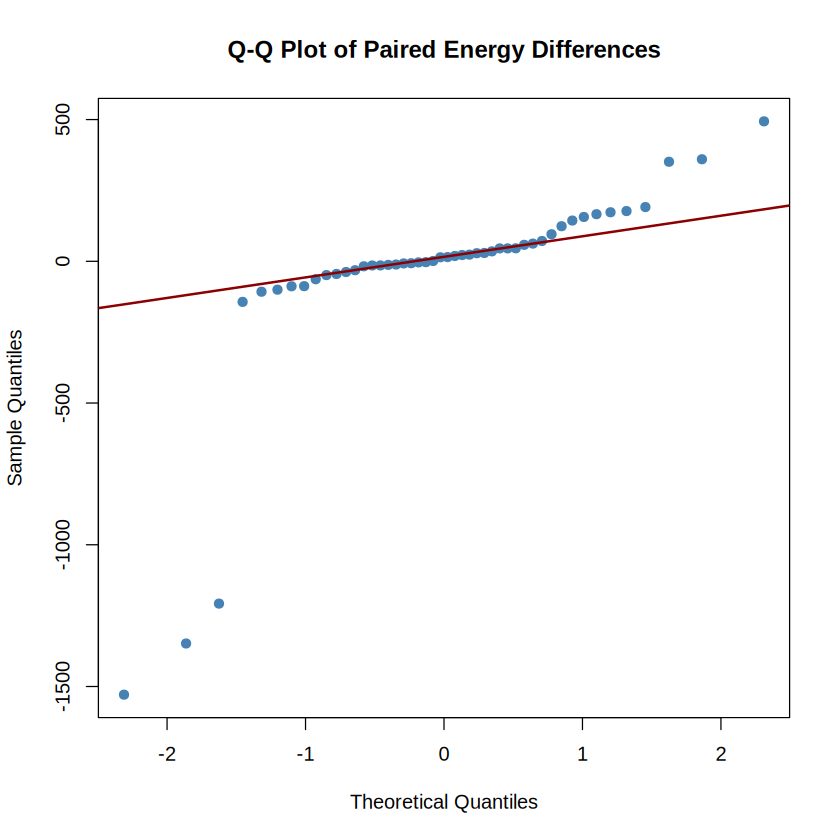

In [192]:
# Check the distribution of paired energy differences
qqnorm(pair_table$dE, main = "Q-Q Plot of Paired Energy Differences",
       pch = 19, col = "steelblue")
qqline(pair_table$dE, col = "darkred", lwd = 2)

In [193]:
library(tidyverse)
# Create a figures folder
dir.create("figures", showWarnings = FALSE)

# Convert deltas to percentages for clearer plotting and reporting
pair_plot <- pair_table %>%
  mutate(
    dE_pct   = dE_rel * 100,
    dT_pct   = dT_rel * 100,
    dP_pct   = dP_rel * 100,
    dCPU_pct = dCPU_rel * 100,
    dMem_pct = dMem_rel * 100,
    # sort data in levels to avoid the data being sorted alphabetically (G1, G18, G19, G2, etc.)
    guideline_id = factor(guideline_id, levels = c("G1", "G2", "G3", "G6", "G18", "G19", "G24", "G27")),
    guideline_family = factor(guideline_family, levels = c("Code Optimization", "Function Calls", "Other")),
    difficulty = factor(difficulty, levels = c("easy", "medium"))
  )

# Summary Statistics Tables

# Overall results of all 48 pairs
summary_overall <- pair_plot %>%
  summarise(
    Metric   = "Total Energy Savings (dE%)",
    N_pairs  = n(),
    Mean     = mean(dE_pct, na.rm = TRUE),
    SD       = sd(dE_pct, na.rm = TRUE),
    Median   = median(dE_pct, na.rm = TRUE),
    IQR      = IQR(dE_pct, na.rm = TRUE),
    Min      = min(dE_pct, na.rm = TRUE),
    Max      = max(dE_pct, na.rm = TRUE)
  )

# Results by guideline (6 pairs each)
summary_guideline <- pair_plot %>%
  group_by(guideline_family, guideline_id) %>%
  summarise(
    N_pairs = n(),
    Mean    = mean(dE_pct, na.rm = TRUE),
    SD      = sd(dE_pct, na.rm = TRUE),
    Median  = median(dE_pct, na.rm = TRUE),
    IQR     = IQR(dE_pct, na.rm = TRUE),
    Min     = min(dE_pct, na.rm = TRUE),
    Max     = max(dE_pct, na.rm = TRUE),
    .groups = "drop"
  )

# Results by family (24 / 12 / 12 pairs)
summary_family <- pair_plot %>%
  group_by(guideline_family) %>%
  summarise(
    N_pairs = n(),
    Mean    = mean(dE_pct, na.rm = TRUE),
    SD      = sd(dE_pct, na.rm = TRUE),
    Median  = median(dE_pct, na.rm = TRUE),
    IQR     = IQR(dE_pct, na.rm = TRUE),
    Min     = min(dE_pct, na.rm = TRUE),
    Max     = max(dE_pct, na.rm = TRUE),
    .groups = "drop"
  )

# Results by difficulty (24 Easy, 24 Medium)
summary_difficulty <- pair_plot %>%
  group_by(difficulty) %>%
  summarise(
    N_pairs = n(),
    Mean    = mean(dE_pct, na.rm = TRUE),
    SD      = sd(dE_pct, na.rm = TRUE),
    Median  = median(dE_pct, na.rm = TRUE),
    IQR     = IQR(dE_pct, na.rm = TRUE),
    Min     = min(dE_pct, na.rm = TRUE),
    Max     = max(dE_pct, na.rm = TRUE),
    .groups = "drop"
  )

# Save summary CSVs
write_csv(summary_overall, "summary_overall.csv")
write_csv(summary_guideline, "summary_by_guideline.csv")
write_csv(summary_family, "summary_by_family.csv")
write_csv(summary_difficulty, "summary_by_difficulty.csv")

cat("--- Summary Tables Exported ---\n\n")
cat("Overall dE%:\n")
print(summary_overall)
cat("\nBy Guideline dE%:\n")
print(summary_guideline)

# Check 4 problems for changes in energy across repetition rounds
sample_problems <- c(3, 49, 125, 442)
p_drift <- runs_with_metrics %>%
  filter(problem %in% sample_problems & variant == "1") %>%
  ggplot(aes(x = repetition, y = total_energy_j, color = treatment)) +
  geom_point(alpha = 0.6, size = 1.8) +
  geom_smooth(method = "loess", se = FALSE, linewidth = 0.8) +
  facet_wrap(~problem, scales = "free_y", labeller = label_both) +
  theme_bw(base_size = 12) +
  labs(
    title = "Energy Consumption across Repetition Rounds",
    subtitle = "Variant 1; selected problems",
    x = "Repetition Round",
    y = "Total Energy (Joules)",
    color = "Treatment"
  )
ggsave("figures/sanity_drift_plot.png", p_drift, width = 8, height = 5, dpi = 300)


# RQ1: Compare changes in energy, runtime and power
rq1_long <- pair_plot %>%
  select(problem, variant, dE_pct, dT_pct, dP_pct) %>%
  pivot_longer(cols = c(dE_pct, dT_pct, dP_pct), names_to = "Metric", values_to = "PercentChange") %>%
  mutate(Metric = recode(Metric,
    "dE_pct" = "Energy (dE%)",
    "dT_pct" = "Runtime (dT%)",
    "dP_pct" = "Power (dP%)"
  ))

p_rq1 <- ggplot(rq1_long, aes(x = Metric, y = PercentChange, fill = Metric)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray40") +
  geom_boxplot(width = 0.45, alpha = 0.7, outlier.shape = 21, outlier.size = 2) +
  geom_jitter(width = 0.12, alpha = 0.4, size = 1.5) +
  theme_bw(base_size = 12) +
  theme(legend.position = "none") +
  labs(
    title = "RQ1: Overall Relative Savings across 48 Code Pairs",
    subtitle = "Positive % = savings; Negative % = regression",
    x = "",
    y = "Relative Change (%)"
  )
ggsave("figures/rq1_metric_distributions.png", p_rq1, width = 6, height = 4.5, dpi = 300)

# Q-Q plot for paired energy differences
p_qq <- ggplot(pair_table, aes(sample = dE)) +
  stat_qq(color = "steelblue", size = 2) +
  stat_qq_line(color = "red", linewidth = 1.5) +
  theme_bw(base_size = 12) +
  labs(
    title = "Normal Q-Q Plot: Paired Energy Differences (dE)",
    x = "Theoretical Quantiles",
    y = "Sample Quantiles"
  )

ggsave("figures/qq_plot_dE.png", p_qq, width = 6, height = 4.5, dpi = 300)

# Save a high-resolution copy
png("figures/qq_plot_dE.png", width = 1600, height = 1400, res = 300)
qqnorm(pair_table$dE, main = "Normality of Paired Energy Differences", xlab = "Theoretical Quantiles", ylab = "Observed Quantiles", pch = 19, col = "steelblue")
qqline(pair_table$dE, col = "darkred", lwd = 2)
dev.off()

# RQ2: Compare energy savings by guideline and difficulty
p_rq2_guidelines <- ggplot(pair_plot, aes(x = guideline_id, y = dE_pct, fill = guideline_family)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray40") +
  geom_boxplot(alpha = 0.7, outlier.shape = 21, width = 0.5) +
  geom_jitter(width = 0.15, alpha = 0.5, size = 1.5) +
  theme_bw(base_size = 12) +
  labs(
    title = "RQ2: Energy Savings by Guideline",
    subtitle = "Positive % = savings; Negative % = regression",
    x = "Guideline ID",
    y = "Energy Savings (dE%)",
    fill = "Family"
  )
ggsave("figures/rq2_energy_by_guideline.png", p_rq2_guidelines, width = 8, height = 4.5, dpi = 300)

p_rq2_difficulty <- ggplot(pair_plot, aes(x = difficulty, y = dE_pct, fill = difficulty)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray40") +
  geom_boxplot(alpha = 0.7, width = 0.4, outlier.shape = 21) +
  geom_jitter(width = 0.12, alpha = 0.5, size = 1.6) +
  theme_bw(base_size = 12) +
  theme(legend.position = "none") +
  labs(
    title = "RQ2: Energy Savings by Problem Difficulty",
    subtitle = "Positive % = savings; Negative % = regression",
    x = "Difficulty Level",
    y = "Energy Savings (dE%)"
  )
ggsave("figures/rq2_energy_by_difficulty.png", p_rq2_difficulty, width = 5, height = 4.5, dpi = 300)


# RQ3: Compare energy savings with CPU and memory changes
p_rq3_mem <- ggplot(pair_plot, aes(x = dMem_pct, y = dE_pct)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray50") +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray50") +
  geom_point(aes(color = guideline_family), size = 2.5, alpha = 0.8) +
  geom_smooth(method = "lm", se = FALSE, color = "black", linetype = "dotted", linewidth = 0.8) +
  theme_bw(base_size = 12) +
  labs(
    title = "RQ3: Energy Change vs. Memory Change",
    subtitle = "Positive % = savings; Negative % = regression",
    x = "Memory Savings (dMem%)",
    y = "Energy Savings (dE%)",
    color = "Guideline Family"
  )
ggsave("figures/rq3_scatter_memory_vs_energy.png", p_rq3_mem, width = 6.5, height = 4.5, dpi = 300)

p_rq3_cpu <- ggplot(pair_plot, aes(x = dCPU_pct, y = dE_pct)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray50") +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray50") +
  geom_point(aes(color = guideline_family), size = 2.5, alpha = 0.8) +
  geom_smooth(method = "lm", se = FALSE, color = "black", linetype = "dotted", linewidth = 0.8) +
  theme_bw(base_size = 12) +
  labs(
    title = "RQ3: CPU Usage Change vs. Energy Savings",
    subtitle = "Positive % = savings; Negative % = regression",
    x = "CPU Change (dCPU%)",
    y = "Energy Savings (dE%)",
    color = "Guideline Family"
  )
ggsave("figures/rq3_scatter_cpu_vs_energy.png", p_rq3_cpu, width = 6.5, height = 4.5, dpi = 300)

cat("Plots saved in the figures folder.\n")

--- Summary Tables Exported ---

Overall dE%:
# A tibble: 1 × 8
  Metric                     N_pairs  Mean    SD Median   IQR   Min   Max
  <chr>                        <int> <dbl> <dbl>  <dbl> <dbl> <dbl> <dbl>
1 Total Energy Savings (dE%)      48 -4.87  66.4   2.04  13.8 -322.  92.3

By Guideline dE%:
# A tibble: 8 × 9
  guideline_family  guideline_id N_pairs    Mean     SD  Median    IQR      Min
  <fct>             <fct>          <int>   <dbl>  <dbl>   <dbl>  <dbl>    <dbl>
1 Code Optimization G1                 6    9.36  10.0    6.70   14.4    -0.428
2 Code Optimization G2                 6    1.81   5.05  -0.854   6.55   -2.14 
3 Code Optimization G3                 6    1.16   5.34   2.36    6.23   -5.62 
4 Code Optimization G6                 6   14.1   11.3   15.6    14.3    -1.79 
5 Function Calls    G18                6   56.4   51.0   87.0    69.2   -17.2  
6 Function Calls    G19                6    6.87   9.02   4.60    5.81   -2.47 
7 Other             G24              

`geom_smooth()` using formula = 'y ~ x'


agg_record_3cf33f21072 
                     2

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


Plots saved in the figures folder.


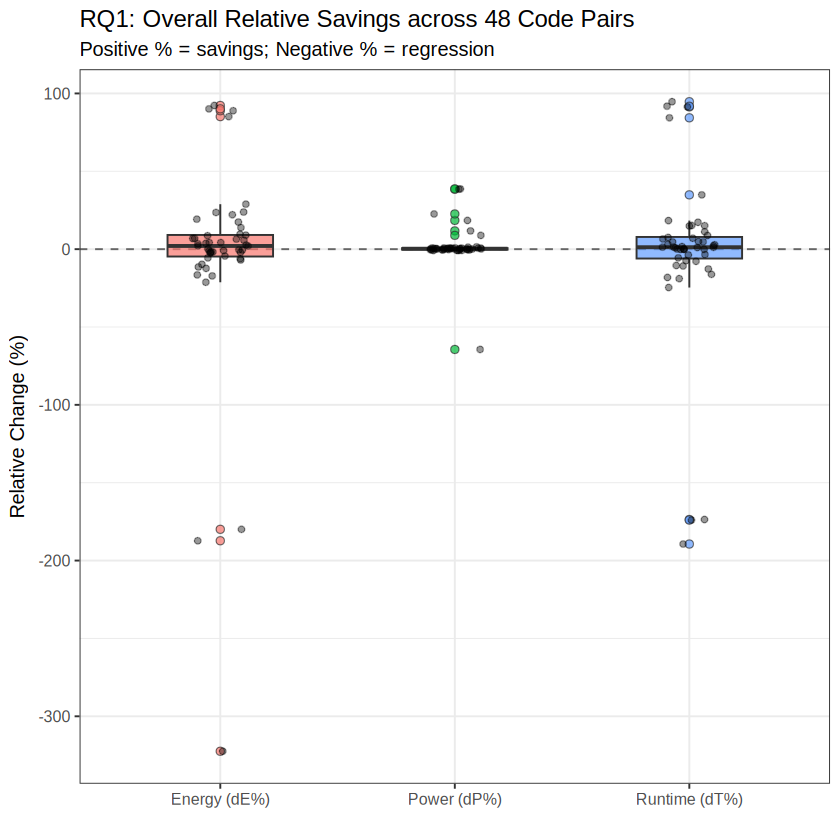

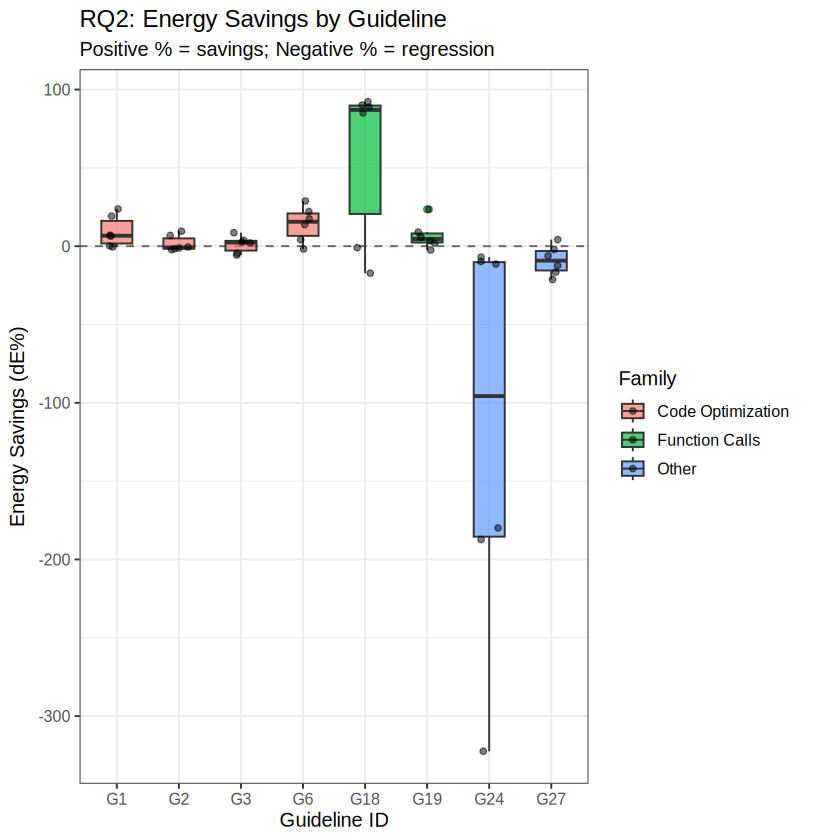

`geom_smooth()` using formula = 'y ~ x'


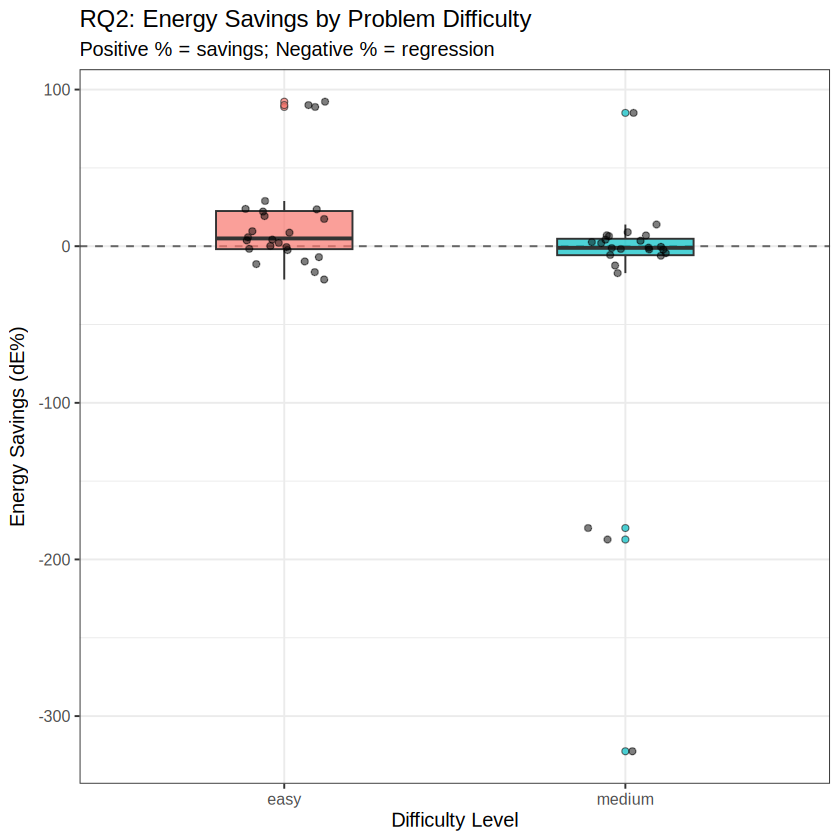

`geom_smooth()` using formula = 'y ~ x'


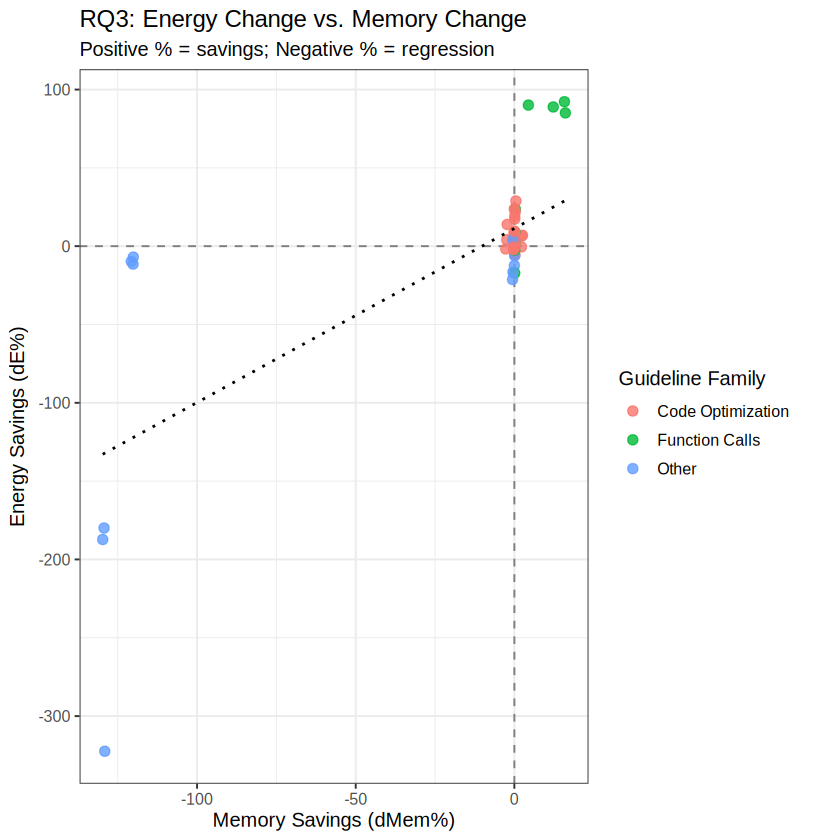

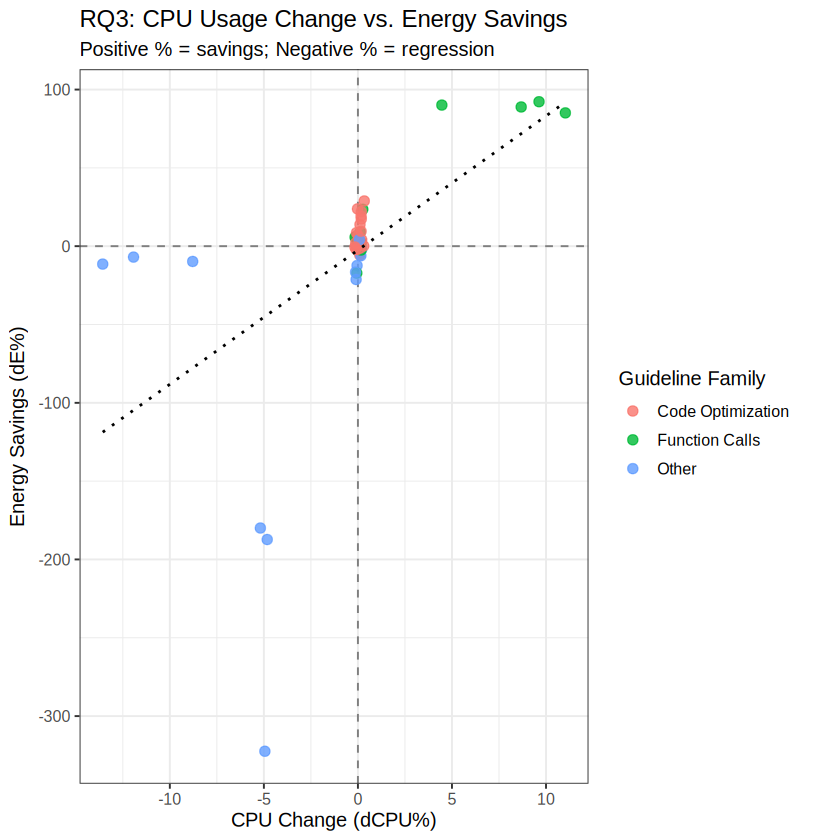

In [194]:
print(p_rq1)
print(p_rq2_guidelines)
print(p_rq2_difficulty)
print(p_rq3_mem)
print(p_rq3_cpu)

In [195]:
# FORMAL STATISTICAL TESTING

library(tidyverse)

# Calculate Cliff's delta and label its magnitude
calc_cliffs_delta <- function(x, y) {
  comp <- outer(x, y, function(a, b) sign(a - b))
  delta <- mean(comp)
  mag <- cut(abs(delta),
             breaks = c(-Inf, 0.147, 0.33, 0.474, Inf),
             labels = c("negligible", "small", "medium", "large"))
  return(list(estimate = delta, magnitude = as.character(mag)))
}

# Calculate Cohen's d and label its magnitude
calc_cohens_d <- function(d) {
  d_val <- mean(d, na.rm = TRUE) / sd(d, na.rm = TRUE)
  mag <- cut(abs(d_val),
             breaks = c(-Inf, 0.2, 0.5, 0.8, Inf),
             labels = c("negligible", "small", "medium", "large"))
  return(list(estimate = d_val, magnitude = as.character(mag)))
}

# Store the main test results for the multiple-testing correction
results_table <- tibble()


# RQ1 / H01: Paired Absolute Energy Change (dE across 48 pairs)


cat("RQ1 / H01: Paired Absolute Energy Change (dE = E_orig - E_mod)\n")

# Check whether the paired differences are normally distributed
shapiro_h01 <- shapiro.test(pair_table$dE)
cat("Shapiro-Wilk normality on dE: W =", round(shapiro_h01$statistic, 4),
    ", p-value =", format.pval(shapiro_h01$p.value, eps = 0.001), "\n")

# Use a Wilcoxon signed-rank test for the paired differences
test_h01 <- wilcox.test(pair_table$dE, mu = 0, exact = FALSE, conf.int = TRUE)
cld_h01  <- calc_cliffs_delta(pair_table$dE, rep(0, length(pair_table$dE)))

cat("Wilcoxon signed-rank test on paired differences:\n")
cat("  V =", round(test_h01$statistic, 2), ", p-value =", format.pval(test_h01$p.value, eps = 0.001), "\n")
cat("  Cliff's delta =", round(cld_h01$estimate, 3), "(", cld_h01$magnitude, ")\n\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H01 (Overall dE != 0)",
  Test_Name = "Wilcoxon signed-rank",
  Statistic = as.numeric(test_h01$statistic),
  p_raw = test_h01$p.value,
  Effect_Metric = "Cliff's delta",
  Effect_Size = cld_h01$estimate,
  Magnitude = cld_h01$magnitude
))

# Additional check using package energy only
test_pkg <- wilcox.test(pair_table$dE_pkg, mu = 0, exact = FALSE)
cat("Sensitivity 1 (Package Energy only dE_pkg): V =", test_pkg$statistic,
    ", p =", format.pval(test_pkg$p.value, eps = 0.001), "\n")

# Additional check using mean energy values
test_mean <- wilcox.test(pair_table$dE_mean, mu = 0, exact = FALSE)
cat("Sensitivity 2 (Mean-aggregated dE_mean): V =", test_mean$statistic,
    ", p =", format.pval(test_mean$p.value, eps = 0.001), "\n\n")


# RQ2: Group Comparisons on Relative Energy Savings (dE_rel)

cat("RQ2: Group Comparisons on Relative Energy Savings (dE_rel)\n")


# Compare the eight guidelines
cat("H02: Between 8 Guidelines\n")
kw_g <- kruskal.test(dE_rel ~ guideline_id, data = pair_table)
eps_sq_g <- (kw_g$statistic - 8 + 1) / (48 - 8)
cat("Kruskal-Wallis across 8 Guidelines: chi-sq =", round(kw_g$statistic, 3),
    ", df =", kw_g$parameter, ", p =", format.pval(kw_g$p.value, eps = 0.001), "\n")
cat("Epsilon-squared (effect size) =", round(eps_sq_g, 3), "\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H02a (Across 8 Guidelines)",
  Test_Name = "Kruskal-Wallis",
  Statistic = as.numeric(kw_g$statistic),
  p_raw = kw_g$p.value,
  Effect_Metric = "Epsilon-squared",
  Effect_Size = as.numeric(eps_sq_g),
  Magnitude = ifelse(eps_sq_g > 0.14, "large", ifelse(eps_sq_g > 0.06, "medium", "small"))
))

# Check pairwise differences, adjusting p-values with Benjamini-Hochberg
cat("\nPost-hoc pairwise Wilcoxon between Guidelines (p.adj < 0.05):\n")
pw_g <- pairwise.wilcox.test(pair_table$dE_rel, pair_table$guideline_id, p.adjust.method = "BH", exact = FALSE)
pw_g_df <- as.data.frame(as.table(pw_g$p.value)) %>% filter(!is.na(Freq)) %>% filter(Freq < 0.05)
if (nrow(pw_g_df) > 0) {
  print(pw_g_df)
} else {
  cat("  No specific pair reached significance at FDR < 0.05.\n")
}

# Compare the three guideline families
cat("\nH02: Between 3 Guideline Families\n")
kw_fam <- kruskal.test(dE_rel ~ guideline_family, data = pair_table)
eps_sq_fam <- (kw_fam$statistic - 3 + 1) / (48 - 3)
cat("Kruskal-Wallis across 3 Families: chi-sq =", round(kw_fam$statistic, 3),
    ", df =", kw_fam$parameter, ", p =", format.pval(kw_fam$p.value, eps = 0.001), "\n")
cat("Epsilon-squared =", round(eps_sq_fam, 3), "\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H02b (Across 3 Families)",
  Test_Name = "Kruskal-Wallis",
  Statistic = as.numeric(kw_fam$statistic),
  p_raw = kw_fam$p.value,
  Effect_Metric = "Epsilon-squared",
  Effect_Size = as.numeric(eps_sq_fam),
  Magnitude = ifelse(eps_sq_fam > 0.14, "large", ifelse(eps_sq_fam > 0.06, "medium", "small"))
))

cat("\nPost-hoc pairwise Wilcoxon between Families (BH-adjusted):\n")
pw_fam <- pairwise.wilcox.test(pair_table$dE_rel, pair_table$guideline_family, p.adjust.method = "BH", exact = FALSE)
print(round(pw_fam$p.value, 4))

# Compare easy and medium problems
cat("\nH02: Easy vs. Medium Problems\n")
test_diff <- wilcox.test(dE_rel ~ difficulty, data = pair_table, exact = FALSE)
easy_vals <- pair_table %>% filter(difficulty == "easy") %>% pull(dE_rel)
med_vals  <- pair_table %>% filter(difficulty == "medium") %>% pull(dE_rel)
cld_diff  <- calc_cliffs_delta(easy_vals, med_vals)

cat("Mann-Whitney U (Wilcoxon Rank-Sum): W =", test_diff$statistic,
    ", p =", format.pval(test_diff$p.value, eps = 0.001), "\n")
cat("Cliff's delta =", round(cld_diff$estimate, 3), "(", cld_diff$magnitude, ")\n\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H02c (Easy vs Medium)",
  Test_Name = "Wilcoxon rank-sum",
  Statistic = as.numeric(test_diff$statistic),
  p_raw = test_diff$p.value,
  Effect_Metric = "Cliff's delta",
  Effect_Size = cld_diff$estimate,
  Magnitude = cld_diff$magnitude
))


# RQ3: Resource Trade-offs (CPU & Memory)

cat("RQ3: Resource Trade-offs (CPU & Memory\n")

# Test whether memory usage changed
test_mem <- wilcox.test(pair_table$dMem_rel, mu = 0, exact = FALSE)
cld_mem  <- calc_cliffs_delta(pair_table$dMem_rel, rep(0, nrow(pair_table)))
cat("H03a (Memory Change dMem_rel != 0): V =", test_mem$statistic,
    ", p =", format.pval(test_mem$p.value, eps = 0.001),
    ", Cliff's delta =", round(cld_mem$estimate, 3), "\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H03 (Memory Change != 0)",
  Test_Name = "Wilcoxon signed-rank",
  Statistic = as.numeric(test_mem$statistic),
  p_raw = test_mem$p.value,
  Effect_Metric = "Cliff's delta",
  Effect_Size = cld_mem$estimate,
  Magnitude = cld_mem$magnitude
))

# Test whether CPU usage changed
test_cpu <- wilcox.test(pair_table$dCPU_rel, mu = 0, exact = FALSE)
cld_cpu  <- calc_cliffs_delta(pair_table$dCPU_rel, rep(0, nrow(pair_table)))
cat("H03 (CPU Change dCPU_rel != 0): V =", test_cpu$statistic,
    ", p =", format.pval(test_cpu$p.value, eps = 0.001),
    ", Cliff's delta =", round(cld_cpu$estimate, 3), "\n\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H03 (CPU Change != 0)",
  Test_Name = "Wilcoxon signed-rank",
  Statistic = as.numeric(test_cpu$statistic),
  p_raw = test_cpu$p.value,
  Effect_Metric = "Cliff's delta",
  Effect_Size = cld_cpu$estimate,
  Magnitude = cld_cpu$magnitude
))

# Check the association between energy savings and memory changes
cor_mem <- cor.test(pair_table$dE_rel, pair_table$dMem_rel, method = "spearman", exact = FALSE)
cat("H03 (Correlation dE_rel vs dMem_rel): rho =", round(cor_mem$estimate, 3),
    ", p =", format.pval(cor_mem$p.value, eps = 0.001), "\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H03 (Correlation dE ~ dMem)",
  Test_Name = "Spearman correlation",
  Statistic = as.numeric(cor_mem$estimate),
  p_raw = cor_mem$p.value,
  Effect_Metric = "Spearman rho",
  Effect_Size = as.numeric(cor_mem$estimate),
  Magnitude = ifelse(abs(cor_mem$estimate) > 0.5, "large", ifelse(abs(cor_mem$estimate) > 0.3, "medium", "small"))
))

cor_cpu <- cor.test(pair_table$dE_rel, pair_table$dCPU_rel, method = "spearman", exact = FALSE)
cat("H03 (Correlation dE_rel vs dCPU_rel): rho =", round(cor_cpu$estimate, 3),
    ", p =", format.pval(cor_cpu$p.value, eps = 0.001), "\n\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H03 (Correlation dE ~ dCPU)",
  Test_Name = "Spearman correlation",
  Statistic = as.numeric(cor_cpu$estimate),
  p_raw = cor_cpu$p.value,
  Effect_Metric = "Spearman rho",
  Effect_Size = as.numeric(cor_cpu$estimate),
  Magnitude = ifelse(abs(cor_cpu$estimate) > 0.5, "large", ifelse(abs(cor_cpu$estimate) > 0.3, "medium", "small"))
))


# Multiple Testing Correction (Benjamini-Hochberg)

results_table <- results_table %>%
  mutate(
    p_adjusted_BH = p.adjust(p_raw, method = "BH"),
    Significant_FDR_05 = ifelse(p_adjusted_BH < 0.05, "YES", "NO")
  )

write_csv(results_table, "statistical_test_results.csv")

cat("Statistical results after Benjamini-Hochberg adjustment\n")


print(results_table %>% select(Hypothesis, Test_Name, p_raw, p_adjusted_BH, Significant_FDR_05, Effect_Metric, Effect_Size, Magnitude))


RQ1 / H01: Paired Absolute Energy Change (dE = E_orig - E_mod)
Shapiro-Wilk normality on dE: W = 0.57 , p-value = < 0.001 
Wilcoxon signed-rank test on paired differences:
  V = 701 , p-value = 0.24856 
  Cliff's delta = 0.083 ( negligible )

Sensitivity 1 (Package Energy only dE_pkg): V = 653 , p = 0.50826 
Sensitivity 2 (Mean-aggregated dE_mean): V = 687 , p = 0.31237 

RQ2: Group Comparisons on Relative Energy Savings (dE_rel)
H02: Between 8 Guidelines
Kruskal-Wallis across 8 Guidelines: chi-sq = 24.796 , df = 7 , p = < 0.001 
Epsilon-squared (effect size) = 0.445 

Post-hoc pairwise Wilcoxon between Guidelines (p.adj < 0.05):
  Var1 Var2       Freq
1  G24   G1 0.02841926
2  G24  G19 0.02841926
3  G24   G2 0.02841926
4   G3  G24 0.02841926
5   G6  G24 0.02841926

H02: Between 3 Guideline Families
Kruskal-Wallis across 3 Families: chi-sq = 20.348 , df = 2 , p = < 0.001 
Epsilon-squared = 0.408 

Post-hoc pairwise Wilcoxon between Families (BH-adjusted):
               Code Optimizati